# Delta hedging, step by step

This notebook walks through the simulator in `src/dhsim`: sell an option at its Black-Scholes price,
delta-hedge it on simulated paths, and see **why** the hedge makes or loses money.

Every section uses a few thousand paths so the notebook runs in about a minute. The full-size runs
behind the README charts come from `python -m dhsim all` and are saved in `output/`.

**Setup** (the package defaults, crypto-like): spot 60,000, implied vol 60%, a 30-day at-the-money call,
zero rates, a 365-day year (the market trades 24/7). We are **short one call** and hedge it with the underlying.

In [1]:
%matplotlib inline
import numpy as np
from IPython.display import display

from dhsim import bs, theory as th
from dhsim.config import Config, merge
from dhsim.experiments import get
from dhsim.hedging import Market, Option, Strategy, run_hedge
from dhsim.paths import GBM

cfg = Config()
S0, K, T, sigma = cfg.market.spot, cfg.strike, cfg.expiry, cfg.vol.implied
print(f"S0 = {S0:,.0f}, K = {K:,.0f}, T = {cfg.option.expiry_days:g} days, sigma_i = {sigma:.0%}")

S0 = 60,000, K = 60,000, T = 30 days, sigma_i = 60%


## 1. The option and its Greeks

With $r = q = 0$ the Black-Scholes PDE reads $\Theta = -\tfrac12\sigma^2 S^2\Gamma$: an option's time decay is
exactly what its gamma earns if the spot moves by $S\sigma\sqrt{dt}$ over $dt$. That move is the hedger's
**breakeven**. Bigger moves favour the long-gamma side and smaller moves favour the short.

In [2]:
g = bs.greeks(S0, K, T, sigma)
day = 1 / cfg.simulation.days_per_year
print(f"price {float(g.price):,.2f}   delta {float(g.delta):.4f}   gamma {float(g.gamma):.3e}")
print(f"vega {float(g.vega) / 100:,.2f} per vol point   theta {float(g.theta) * day:,.2f} per day")
print(f"theta + 1/2 sigma^2 S^2 gamma = {float(g.theta + 0.5 * sigma**2 * S0**2 * g.gamma):.1e}   (the BS PDE)")
print(f"breakeven daily move: +/-{S0 * sigma * np.sqrt(day):,.0f}")

rng = np.random.default_rng(0)
s_T = S0 * np.exp(-0.5 * sigma**2 * T + sigma * np.sqrt(T) * rng.standard_normal(1_000_000))
payoff = np.maximum(s_T - K, 0.0)
print(f"Monte Carlo price {payoff.mean():,.2f} +/- {payoff.std() / 1000:.2f} (1 SE)")

price 4,112.36   delta 0.5343   gamma 3.851e-05
vega 68.37 per vol point   theta -68.37 per day
theta + 1/2 sigma^2 S^2 gamma = 7.3e-12   (the BS PDE)
breakeven daily move: +/-1,884
Monte Carlo price 4,121.14 +/- 6.68 (1 SE)


## 2. One path: theta earned vs gamma paid

`run_hedge` sells the call at $BS(\sigma_i)$, holds $\Delta$ units of spot (rebalanced hourly), keeps the
cash in an account at $r$, and settles at expiry. The P&L attribution is exact:

$$\text{PnL} = \text{premium} + \text{payoff} + \textstyle\sum_k h_k\,\Delta S_k + \text{financing} + \text{costs}.$$

Marking the option at $\sigma_i$, each step splits into **theta** ($-\Theta\,dt$, collected by the short),
**gamma** ($\tfrac12\Gamma\,\Delta S^2$, paid by the short) and a small third-order residual.

In [3]:
option, market = Option(K, T, "call", -1.0), Market(S0)
path = GBM(0.6).simulate(S0, T, 720, 1, np.random.default_rng(3))
res = run_hedge(path.S, path.t, option, market, sigma, decompose=True, record=True)

print("attribution")
for name, value in res.attribution().items():
    print(f"  {name:>9s} {value[0]:+12,.2f}")
print(f"  {'total':>9s} {res.pnl[0]:+12,.2f}\n")
print("decomposition")
for name, value in res.decomposition().items():
    print(f"  {name:>9s} {value[0]:+12,.2f}")

attribution
    premium    +4,112.36
     payoff   -18,909.54
      hedge   +14,802.82
  financing        +0.00
      costs        -0.00
      total        +5.64

decomposition
      theta    +1,559.60
      gamma    -1,552.31
   mismatch        +0.00
  financing        +0.00
      costs        -0.00
   residual        -1.65


The call finished deep in the money, so the payoff dwarfs the premium. The hedge bought spot on the way
up and covered it, and the total is close to zero because this path realised about 60% vol, the same as
implied. Per step, theta + gamma is exactly $\tfrac12\Gamma S^2(\sigma_i^2\,dt - R^2)$ with $R$ the step return.
The short wins a step when the squared move comes in below what implied vol priced.

max |theta + gamma - 1/2 Gamma S^2 (sigma^2 dt - R^2)| = 7.1e-15


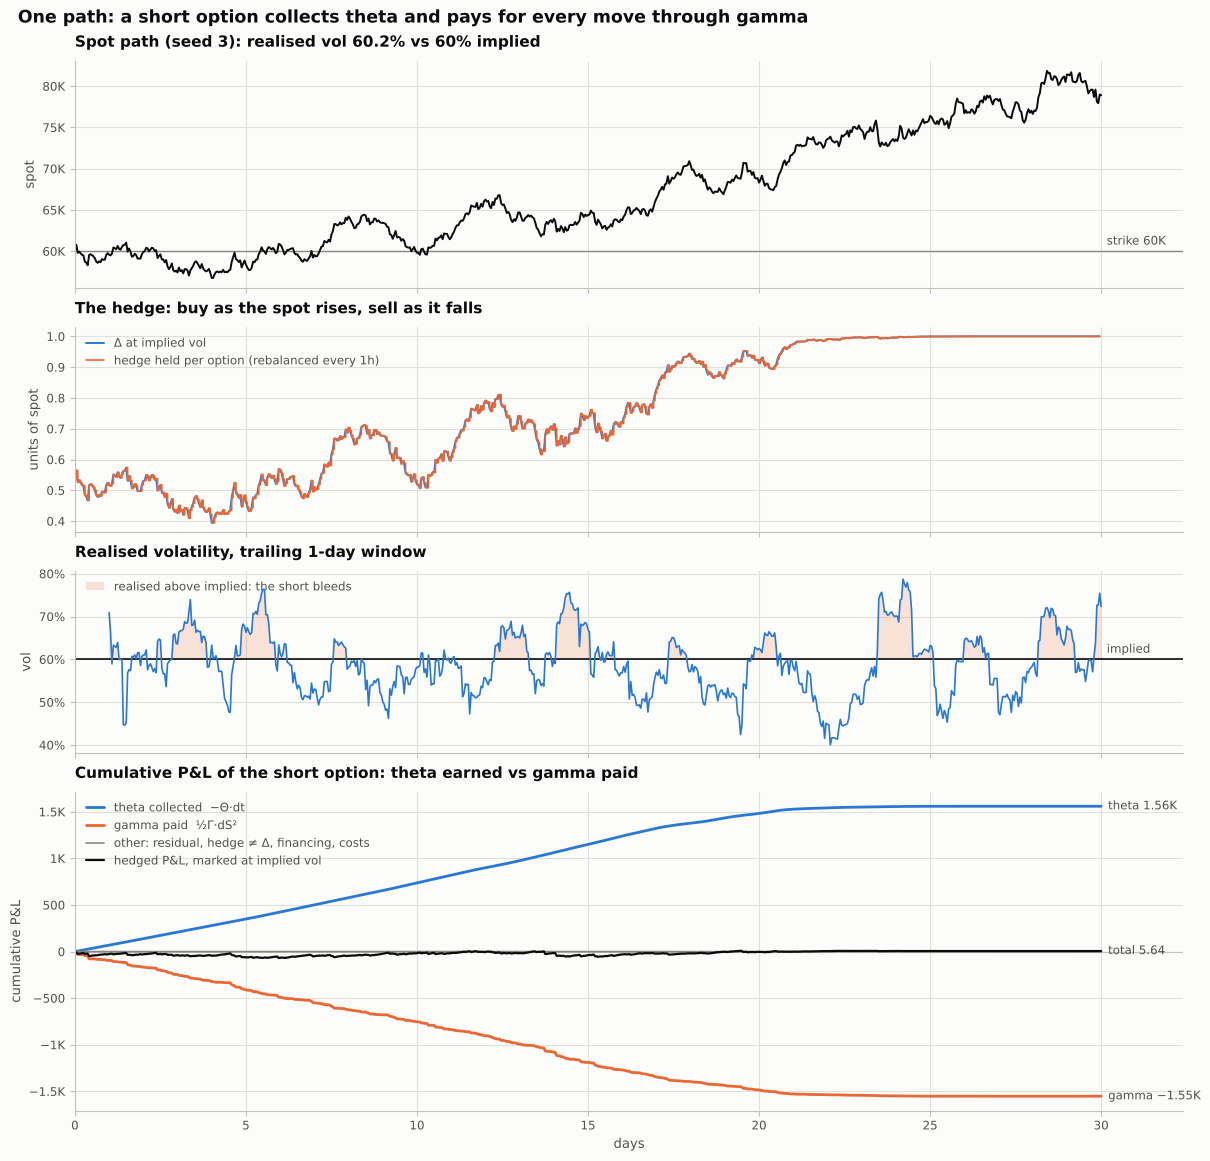

In [4]:
st = res.steps
R = np.diff(st["S"][0]) / st["S"][0, :-1]
gap = 0.5 * st["gamma_greek"][0] * st["S"][0, :-1] ** 2 * (sigma**2 * np.diff(st["t"]) - R**2)
print("max |theta + gamma - 1/2 Gamma S^2 (sigma^2 dt - R^2)| =",
      f"{np.abs(st['theta'][0] + st['gamma'][0] - gap).max():.1e}")
display(get("path")(cfg, verbose=False).figures["path"])

## 3. Hedge frequency changes the risk, not the expected P&L

With $\sigma_r = \sigma_i$ the hedged P&L has mean zero at **any** rebalancing frequency (the discounted hedge
gains are martingale increments). Its standard deviation falls like $1/\sqrt N$. Derman & Kamal's
rule for an at-the-money option is $\text{std} \approx \sqrt{\pi/4}\cdot\text{vega}\cdot\sigma/\sqrt N$, the special case of
$\text{Var} \approx \tfrac12\sigma^4\,\Delta t\int_0^T E[(S^2\Gamma)^2]\,dt$, which `dhsim.theory` evaluates in closed form for any strike.

every   30d: mean    +11.5 +/-  49.0   std   3097.4   Derman-Kamal   3635.5
every  7.5d: mean     +9.4 +/-  26.3   std   1661.6   Derman-Kamal   1817.8
every    1d: mean     +0.1 +/-  10.2   std    646.8   Derman-Kamal    663.8
every    1h: mean     +2.3 +/-   2.1   std    130.4   Derman-Kamal    135.5
every  5min: mean     +1.8 +/-   0.6   std     38.4   Derman-Kamal     39.1
  [ok] mean P&L vs theory: |z| < 3.38 at every N (Bonferroni, 1% family-wise for 14 means); largest |z| = 3.28 at N=2880
  [ok] std vs Derman-Kamal (N >= 30): sim/theory within 4.3% (worst at N=240)
  [FLAG] std vs Derman-Kamal (N < 30): sim/theory = 0.85 at N=1, 0.89 at N=2, 0.91 at N=4, 0.90 at N=8, 0.93 at N=15 - the formula is leading order in 1/N and overstates the std when the option is hedged only a few times
  [ok] std ~ N^-1/2: fitted slope -0.498 for N >= 30


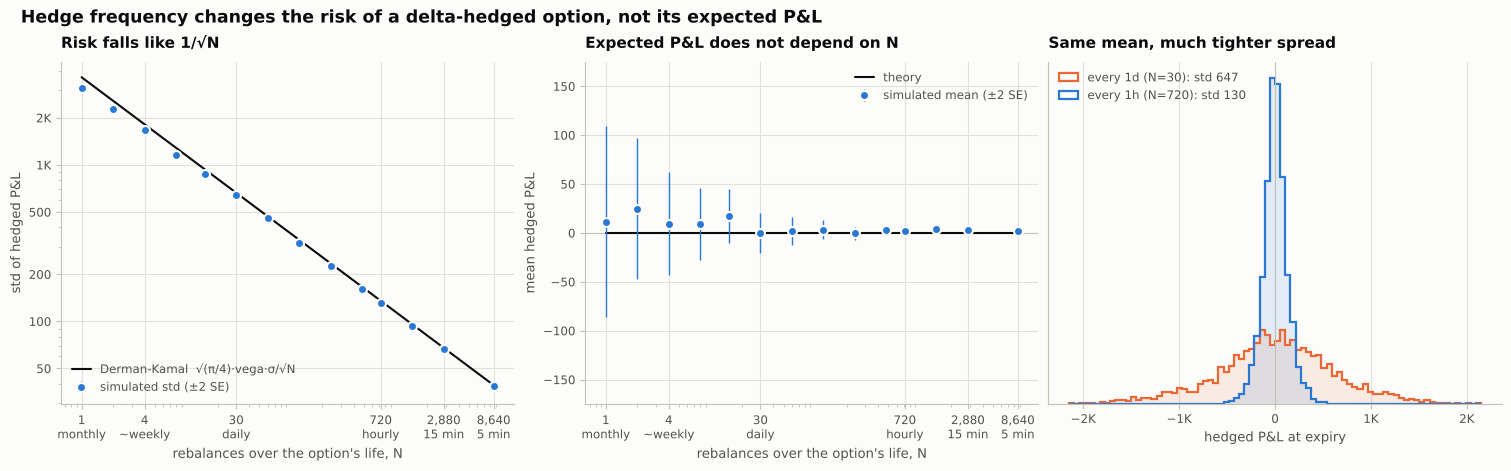

In [5]:
small = merge(cfg, {"frequency": {"paths": 4000}, "volgap": {"paths": 3000},
                    "costs_tradeoff": {"paths": 3000}, "models": {"paths": 3000}})
freq = get("frequency")(small, verbose=False)
for r in freq.rows:
    if r["rebalances"] in (1, 4, 30, 720, 8640):
        print(f"every {r['interval']:>5s}: mean {r['mean']:+8.1f} +/- {r['se_mean']:5.1f}   "
              f"std {r['std']:8.1f}   Derman-Kamal {r['std_derman_kamal']:8.1f}")
print(freq.checks.report())
display(freq.figures["frequency"])

A statistical aside: with only 4,000 paths, a few of the high-frequency means above sit 2-3
standard errors from zero. Fourteen frequencies on the *same* paths are 14 correlated tests, so the checks use a
Bonferroni threshold (|z| < 3.38 for a 1% family-wise false-flag rate). Eight further independent seeds
(160,000 paths) give a pooled z of -0.35 at N = 1,440: the expected P&L really does not depend on N.

## 4. Realised vs implied volatility, and which vol to hedge with

A delta-hedged short option is a bet on realised volatility. Selling at $\sigma_i$ when the paths realise $\sigma_r$:

* hedging with the **realised-vol delta** replicates the option, so it locks in $BS(\sigma_i) - BS(\sigma_r)$ on every path;
* hedging with the **implied-vol delta** earns the same on average, but path by path:
  $\text{PnL} = \tfrac12\int \Gamma_i S^2(\sigma_i^2 - \sigma_r^2)\,dt$. The gap is weighted by the dollar gamma the path happened to hold.

sigma_r 0.40: BS(i)-BS(r)  +1368.9 | implied-vol delta  +1374.6 (std   421) | realised-vol delta  +1369.6 (std    90)
sigma_r 0.50: BS(i)-BS(r)   +684.1 | implied-vol delta   +687.1 (std   260) | realised-vol delta   +684.9 (std   112)
sigma_r 0.60: BS(i)-BS(r)     +0.0 | implied-vol delta     +1.2 (std   135) | realised-vol delta     +1.2 (std   135)
sigma_r 0.70: BS(i)-BS(r)   -683.3 | implied-vol delta   -683.1 (std   323) | realised-vol delta   -681.5 (std   157)
sigma_r 0.80: BS(i)-BS(r)  -1365.5 | implied-vol delta  -1366.1 (std   624) | realised-vol delta  -1363.3 (std   179)
  [ok] mean P&L vs theory (implied-vol delta): |z| < 3.26 for every sigma_r (largest 0.74)
  [ok] mean P&L vs theory (realised-vol delta): |z| < 3.26 for every sigma_r (largest 0.69)
  [ok] std vs theory (realised-vol delta): sim/theory within 0.9% (worst at sigma_r=0.65)
  [ok] std vs theory (implied-vol delta): sim/theory within 2.8% (worst at sigma_r=0.65)
  [ok] implied-vol hedge minus (1/2) int Gamma S

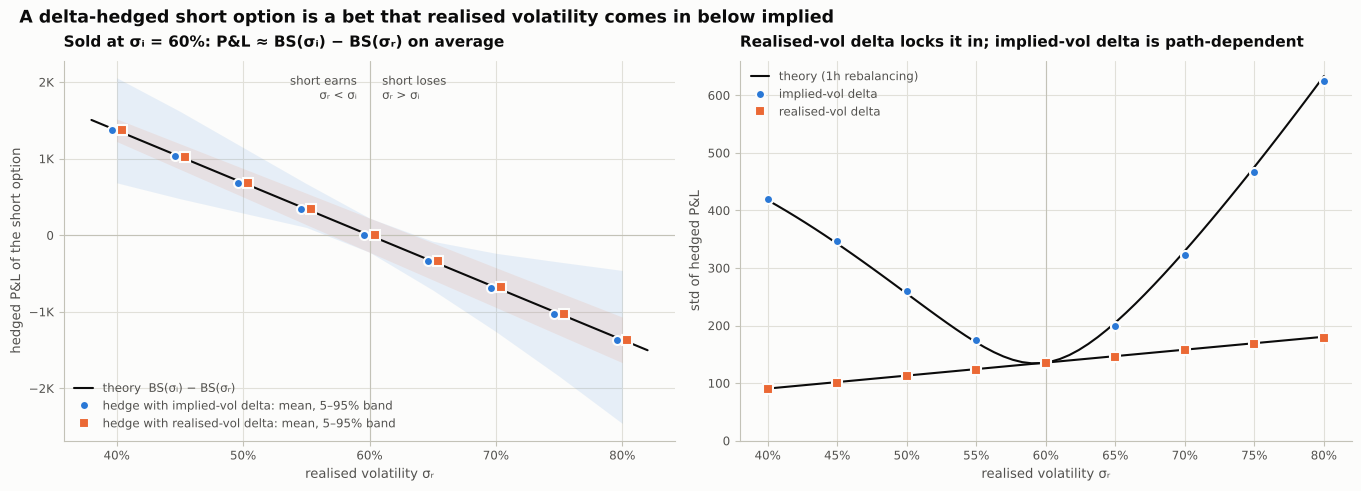

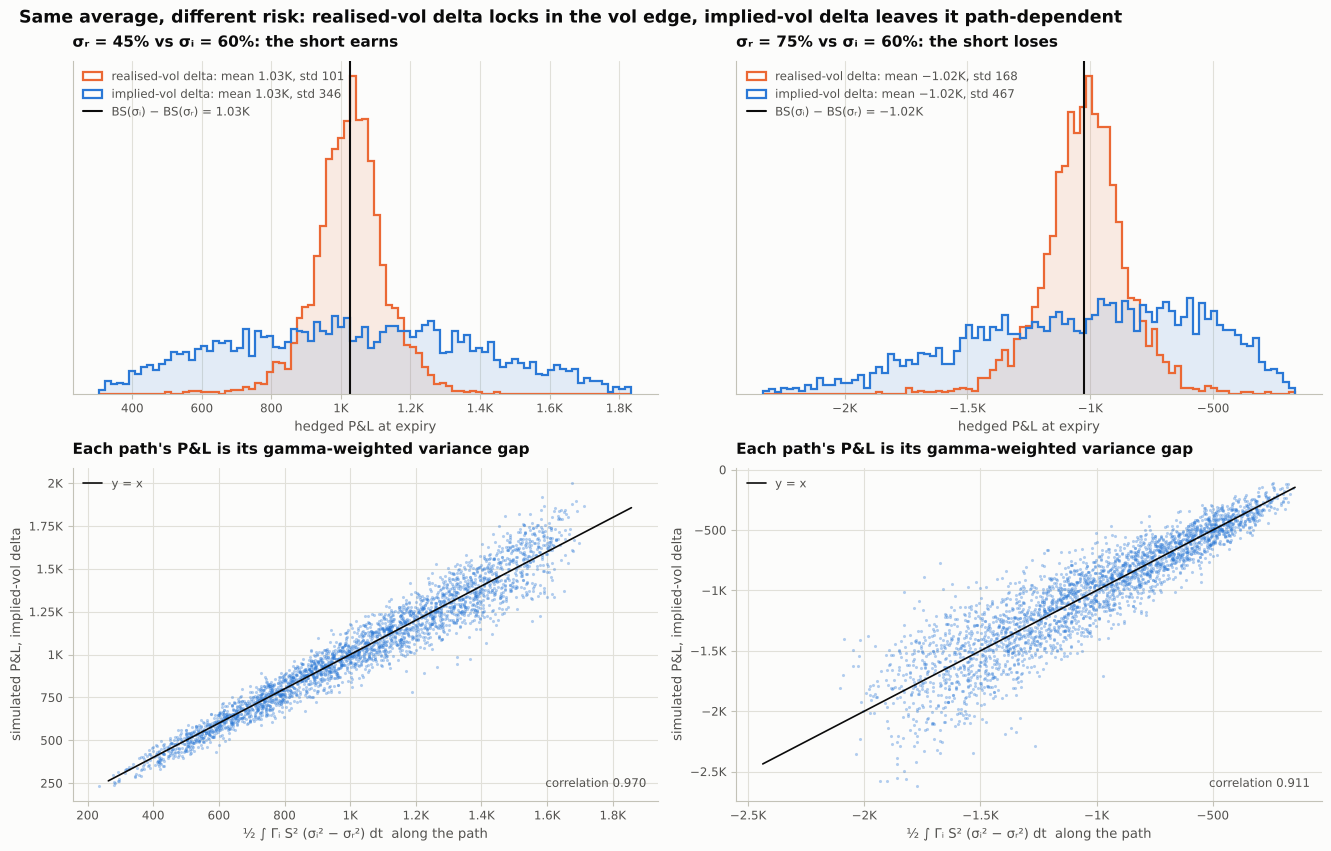

In [6]:
vg = get("volgap")(small, verbose=False)
for r in vg.rows[::2]:
    print(f"sigma_r {r['sigma_r']:.2f}: BS(i)-BS(r) {r['theory_lockin']:+8.1f} | implied-vol delta "
          f"{r['mean_implied']:+8.1f} (std {r['std_implied']:5.0f}) | realised-vol delta "
          f"{r['mean_realised']:+8.1f} (std {r['std_realised']:5.0f})")
print(vg.checks.report())
display(vg.figures["volgap"])
display(vg.figures["volgap_distributions"])

## 5. Transaction costs: an optimal frequency, and bands

Each rebalance trades about $\Gamma\,|\Delta S|$ of spot, so proportional costs grow like $\sqrt N$ while the hedging
variance falls like $1/N$. The mean-variance objective $J = -E[\text{PnL}] + \kappa\,\text{Var}/\text{premium}$ is U-shaped.
Costs are path-dependent too: paths that stay near the strike carry more gamma and pay more, so with costs
the risk itself turns back up at high frequency. Band hedging (trade only when $|\Delta - h|$ exceeds a band)
spends the trading budget where gamma is.

theory optimum: N* = 76 (every 9.47h), J = 156.6
simulated best fixed schedule: every 12h, J = 164.7
best band: band 0.05 (edge), J = 119.9
  [ok] expected cost vs Leland-style theory: sim/theory within 2.5% at every N (worst at N=4)
  [ok] std vs leading-order theory (N >= 30): sim/theory within 3.8% (worst at N=30)
  [ok] optimal frequency: simulation vs theory: simulated optimum N=60 (every 12h), theory N*=76 (every 9.47h); grid neighbours [30, 120]
  [ok] minimum objective: simulation vs theory: J_sim = 164.7 vs J_theory = 156.6 (5.2%)
  [ok] band hedging beats the best fixed schedule: best band band 0.05 (edge): J = 119.9 vs 164.7 for every 12h (27% lower)


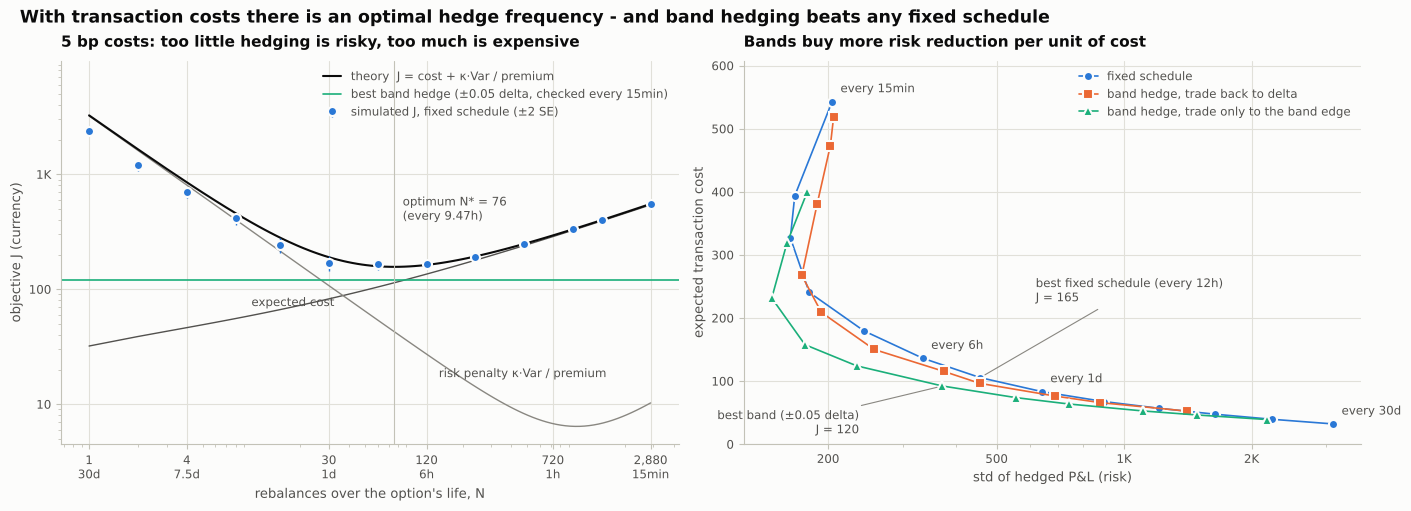

In [7]:
ct = get("costs")(small, verbose=False)
best = ct.summary["best_fixed"]
print(f"theory optimum: N* = {ct.summary['theory_optimum']['rebalances']} "
      f"(every {ct.summary['theory_optimum']['interval']}), J = {ct.summary['theory_optimum']['objective']:.1f}")
print(f"simulated best fixed schedule: {best['label']}, J = {best['objective']:.1f}")
print(f"best band: {ct.summary['best_band']['label']}, J = {ct.summary['best_band']['objective']:.1f}")
print(ct.checks.report())
display(ct.figures["costs"])

## 6. Where the Black-Scholes hedge breaks: jumps and stochastic volatility

Same expected realised variance, three models. Under GBM, finer hedging removes the risk. A Merton jump
moves the spot before the hedge can follow, and Heston makes realised variance itself random. Neither
risk shrinks with more rebalancing.

    gbm every    1d: mean   +13.4  std   635.9  skew -0.20  1% ES    -2,094
    gbm every    1h: mean    -0.5  std   132.4  skew +0.04  1% ES      -425
    gbm every 15min: mean    +1.0  std    67.3  skew +0.25  1% ES      -208
 merton every    1d: mean  +148.3  std  1763.8  skew -3.39  1% ES    -9,976
 merton every    1h: mean  +149.2  std  1722.5  skew -3.98  1% ES   -10,288
 merton every 15min: mean  +150.1  std  1719.0  skew -4.01  1% ES   -10,280
 heston every    1d: mean   +74.6  std  1063.4  skew -0.63  1% ES    -4,002
 heston every    1h: mean   +86.3  std   850.3  skew -0.33  1% ES    -2,974
 heston every 15min: mean   +84.8  std   840.7  skew -0.30  1% ES    -2,884


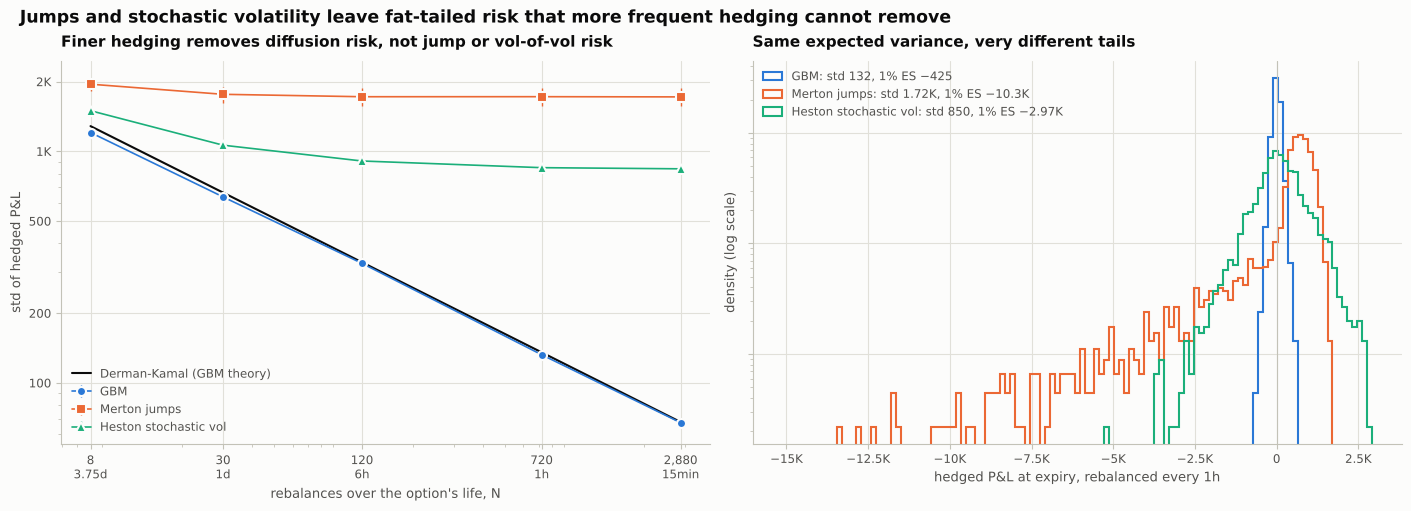

In [8]:
md_ = get("models")(small, verbose=False)
for r in md_.rows:
    if r["rebalances"] in (30, 720, 2880):
        print(f"{r['model']:>7s} every {r['interval']:>5s}: mean {r['mean']:+7.1f}  std {r['std']:7.1f}  "
              f"skew {r['skew']:+5.2f}  1% ES {r['es01']:9,.0f}")
display(md_.figures["models"])

## Takeaways

* **Short option + delta hedge = short volatility.** Theta pays $\tfrac12\Gamma S^2\sigma_i^2\,dt$ and gamma costs $\tfrac12\Gamma S^2 R^2$
  on every step. The P&L is the gamma-weighted gap between implied and realised variance.
* **Hedge frequency is a risk dial, not a return dial.** The mean does not move. The std falls like $1/\sqrt N$, matching Derman-Kamal.
* **Which vol to hedge with matters.** The realised-vol delta locks in $BS(\sigma_i) - BS(\sigma_r)$ (if you knew $\sigma_r$).
  The implied-vol delta earns it on average but path-dependently.
* **Costs create an optimum.** Costs grow like $\sqrt N$ and variance falls like $1/N$, which gives a U-shaped objective, and bands beat fixed schedules.
* **Jumps and vol-of-vol** leave fat-tailed residual risk that no rebalancing frequency removes.